# Proyecto Computacional: Análisis Semántico Latente (LSA) usando SVD
## IMT2230 - Álgebra Lineal Avanzada y Modelamiento
### Pontificia Universidad Católica de Chile

* **Profesor:** Alexander Kozachinskiy
* **Ayudante:** Victoria Otárola
* **Estudiante:** Damián Bravo (y grupo)
* **Repositorio GitHub:** [https://github.com/damian11daba/proyecto-avanzada-y-modelamiento.git](https://github.com/damian11daba/proyecto-avanzada-y-modelamiento.git)

---

## Resumen del Proyecto
En este trabajo aplicamos las herramientas del **Álgebra Lineal Avanzada**, específicamente la **Descomposición en Valores Singulares (SVD)** y el **Teorema de Eckart-Young-Mirsky**, para descubrir la estructura semántica latente (*Latent Semantic Analysis*, LSA) en una colección de $n = 200$ artículos científicos indexados en **arXiv** provenientes de 4 disciplinas contrastantes:
1. **Inteligencia Artificial** (`cs.AI`)
2. **Astrofísica y Cosmología** (`astro-ph.CO`)
3. **Genómica y Biología Computacional** (`q-bio.GN`)
4. **Finanzas Cuantitativas** (`q-fin.PM`)

El objetivo central es construir una matriz término-documento $A \in \mathbb{R}^{m \times n}$ mediante ponderación TF-IDF, aplicar SVD para proyectar términos y documentos en subespacios de dimensión reducida, verificar rigurosamente la equivalencia algebraica de las proyecciones y contrastar los resultados con nuestra hipótesis inicial.

In [1]:
# Configuración del entorno e importación de librerías
import sys
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Añadir directorio raíz al path para importar módulos auxiliares
sys.path.append(os.path.abspath('..'))
from src.preprocessing import build_term_document_matrix, DOMAIN_STOPWORDS
from src.svd_analysis import (
    compute_svd,
    compute_singular_spectrum_metrics,
    project_terms_2d,
    project_documents_2d
)
from src.semantic_exploration import (
    get_latent_representations,
    find_nearest_terms,
    find_nearest_documents,
    extract_component_topics
)

# Estilo gráfico sobrio para publicaciones
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120
print("Entorno configurado correctamente.")

Entorno configurado correctamente.


---
## Paso 1 – Elección y Descripción del Corpus

### Justificación de la Elección
Para este proyecto seleccionamos un corpus de **200 abstracts científicos de acceso abierto** obtenidos mediante la API oficial de **arXiv** (`export.arxiv.org`). Se eligieron 50 documentos por cada una de 4 categorías representativas del modelamiento matemático contemporáneo:

1. **Inteligencia Artificial (`cs.AI`)**: Documentos sobre aprendizaje por refuerzo, modelos de lenguaje, agentes autónomos y redes neuronales.
2. **Astrofísica y Cosmología (`astro-ph.CO`)**: Investigaciones sobre materia oscura, radiación cósmica de fondo, galaxias y lentes gravitacionales.
3. **Genómica y Biología Computacional (`q-bio.GN`)**: Artículos sobre secuenciación de ARN/ADN, expresión génica, biología celular y regulación genética.
4. **Finanzas Cuantitativas (`q-fin.PM`)**: Modelos estocásticos de portafolios, fijación de precios de activos, primas de riesgo y volatilidad de mercado.

### Reproducibilidad y Apertura
El corpus es $100\%$ público y reproducible. Incluimos el script `src/download_corpus.py` para consultar la API de arXiv y los datos ya descargados y fijados en `data/corpus.csv` para garantizar reproducibilidad exacta e independiente de la red.

In [2]:
# Cargar corpus y visualizar resumen estadístico
df = pd.read_csv('../data/corpus.csv')
print(f"Total de documentos cargados: {len(df)}")

# Tabla resumen por categoría
summary = df.groupby(['category_code', 'category_name']).agg(
    Documentos=('doc_id', 'count'),
    Palabras_Promedio=('word_count', 'mean'),
    Min_Palabras=('word_count', 'min'),
    Max_Palabras=('word_count', 'max'),
    Std_Palabras=('word_count', 'std')
).round(2).reset_index()

summary

Total de documentos cargados: 200


,category_code,category_name,Documentos,Palabras_Promedio,Min_Palabras,Max_Palabras,Std_Palabras
0,astro-ph.CO,Astrofísica y Cosmología,50,210.10,108,292,44.26
1,cs.AI,Inteligencia Artificial,50,207.76,103,294,42.08
2,q-bio.GN,Genómica y Biología Computacional,50,207.36,124,324,42.06
3,q-fin.PM,Finanzas Cuantitativas,50,190.80,40,301,61.47


---
## Paso 2 – Hipótesis Inicial

> **Hipótesis del Grupo:**
> 1. **Estructura Espectral:** Debido al decaimiento de ley de potencias característico del lenguaje natural, anticipamos que los primeros valores singulares ($\sigma_1, \sigma_2, \dots, \sigma_k$) concentrarán una porción significativa de la masa espectral (un "codo" marcado en las primeras 4 a 20 componentes).
> 2. **Primera Componente Singular ($u_1, v_1$):** El primer vector singular no discriminará temáticas, sino que capturará un factor de escala común correspondiente a la longitud y al vocabulario académico ubicuo compartido por todos los abstracts (*"data", "model", "analysis", "results"*).
> 3. **Ejes Semánticos Ortogonales ($u_2, u_3, u_4$):** Esperamos que las componentes 2 y 3 capturen las máximas fuentes de varianza temática, logrando separar nítidamente la física/astrofísica de las finanzas y de la biología.
> 4. **Términos Interdisciplinarios:** Palabras polimórficas como *"model", "network", "system", "dynamics"* ocuparán posiciones cercanas al origen en el plano semántico latente, al estar presentes en múltiples disciplinas.

---
## Paso 3 – Preprocesamiento del Texto

Para construir un vocabulario representativo y filtrar ruido estocástico se adoptaron las siguientes decisiones de preprocesamiento:
1. **Normalización:** Conversión a minúsculas, eliminación de caracteres no alfabéticos y puntuación residual.
2. **Stopwords:** Se eliminaron las palabras vacías estándar en inglés (`scikit-learn`), complementadas con una lista de términos genéricos de redacción científica (*paper, study, propose, method, results, etc.*) que inducirían correlaciones artificiales no informativas.
3. **Filtrado por Frecuencia de Documento:**
   - `min_df = 3`: Se descartan términos que aparecen en menos de 3 documentos (erratas tipográficas, nombres propios aislados, símbolos matemáticos raros).
   - `max_df = 0.60`: Se excluyen palabras que aparecen en más del 60% de los documentos (ubicuas).
4. **TF-IDF Sublineal:** En lugar de conteos crudos, se calcula la frecuencia de término sublineal $1 + \log(\text{tf})$ multiplicada por la frecuencia inversa de documento suavizada:
$$\text{TF-IDF}(t, d) = (1 + \log(\text{tf}(t, d))) \times \left( \log \frac{1 + n}{1 + \text{df}(t)} + 1 \right)$$
seguido de normalización Euclídea ($L_2$) para desacoplar el efecto de la longitud del texto.

In [3]:
# Ejecutar preprocesamiento y construcción de vocabulario
A, vocab, df_docs, vectorizer = build_term_document_matrix(
    data_path="../data/corpus.csv",
    min_df=3,
    max_df=0.60,
    sublinear_tf=True
)

m, n = A.shape
print(f"Dimensiones de la matriz textual A: {m} términos x {n} documentos")
print(f"Primeros 15 términos del vocabulario: {vocab[:15]}")

Preprocesamiento completado con éxito:
 - Tamaño del vocabulario m (filas): 1907 términos
 - Cantidad de documentos n (columnas): 200 documentos
 - Dimensiones de la matriz textual A: (1907, 200)
 - Densidad de la matriz: 3.71% de elementos no nulos
Dimensiones de la matriz textual A: 1907 términos x 200 documentos
Primeros 15 términos del vocabulario: ['ability' 'ablations' 'absorption' 'abundance' 'acceleration' 'access'
 'accessibility' 'accommodates' 'account' 'accounting' 'accumulate'
 'accuracy' 'accurate' 'accurately' 'achieved']


---
## Paso 4 – Construcción de la Matriz Textual $A$

### Orientación de la Matriz
En la formulación canónica del Análisis Semántico Latente en álgebra lineal, la matriz textual $A$ tiene dimensión **$m \times n$**, donde:
* **$m$** es el número de términos del vocabulario (filas: $i = 1, \dots, m$).
* **$n$** es el número de documentos del corpus (columnas: $j = 1, \dots, n$).

El elemento $A_{ij}$ representa la importancia relativa (peso TF-IDF) del término $i$ en el documento $j$.

> **Nota técnica sobre scikit-learn:** `TfidfVectorizer.fit_transform()` genera por defecto una matriz de dimensiones $(n \times m)$ con documentos en las filas. Para cumplir con la convención del curso, transponemos explícitamente dicha matriz:
$$A = X^T \in \mathbb{R}^{m \times n}$$

---
## Paso 5 – Cálculo de la Descomposición SVD

Calculamos la SVD compacta de la matriz $A \in \mathbb{R}^{m \times n}$ ($m \ge n$):
$$A = U \Sigma V^T = \sum_{r=1}^n \sigma_r u_r v_r^T$$

* **Parámetros:** Se utilizó `scipy.linalg.svd(A, full_matrices=False)` / `numpy.linalg.svd`.
* **Dimensiones:**
  * $U \in \mathbb{R}^{m \times n}$: Matriz de vectores singulares izquierdos. Sus columnas $\{u_1, \dots, u_n\}$ forman una base ortonormal para el espacio de columnas de $A$.
  * $\Sigma \in \mathbb{R}^{n \times n}$: Matriz diagonal con los valores singulares $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_n \ge 0$.
  * $V^T \in \mathbb{R}^{n \times n}$: Matriz con los vectores singulares derechos transpuestos. Las columnas de $V$ $\{v_1, \dots, v_n\}$ forman una base ortonormal para el espacio de filas de $A$.

In [4]:
# Cálculo de la SVD y validación de propiedades algebraicas
U, S, Vt = compute_svd(A)
V = Vt.T

print(f"Dimensiones de U: {U.shape}")
print(f"Cantidad de valores singulares en S: {len(S)}")
print(f"Dimensiones de V^T: {Vt.shape}")
print(f"Top 5 valores singulares mayores: {np.round(S[:5], 4)}")
print(f"Valor singular mínimo: {S[-1]:.4f}")


Descomposición SVD calculada:
 - Matriz A: (1907, 200)
 - Matriz U (vectores singulares por la izquierda): (1907, 200)
 - Vector S (valores singulares sigma_r): (200,)
 - Matriz V^T (vectores singulares por la derecha traspuestos): (200, 200)
 - Matriz V: (200, 200)
 - Error de ortonormalidad U^T U - I: 2.22e-15
 - Error de ortonormalidad V^T V - I: 2.00e-15
 - Error de reconstrucción Frobenius ||A - U Sigma V^T||_F: 3.91e-14
Dimensiones de U: (1907, 200)
Cantidad de valores singulares en S: 200
Dimensiones de V^T: (200, 200)
Top 5 valores singulares mayores: [3.092  2.0031 1.8353 1.5786 1.4621]
Valor singular mínimo: 0.6091


---
## Paso 6 – Análisis de Valores Singulares y Selección de $k$

### Justificación Teórica de $k$ (Teorema de Eckart-Young-Mirsky)
El teorema fundamental de Eckart-Young-Mirsky establece que la mejor aproximación de rango $k$ para $A$ bajo la norma de Frobenius $\|\cdot\|_F$ y la norma espectral $\|\cdot\|_2$ es:
$$A_k = U_k \Sigma_k V_k^T = \sum_{r=1}^k \sigma_r u_r v_r^T$$
con un error residual exacto:
$$\|A - A_k\|_F = \sqrt{\sum_{r=k+1}^n \sigma_r^2}$$

Para seleccionar $k$, analizamos:
1. **La tasa de decaimiento:** En los datos textuales, el decaimiento inicial es abrupto; $\sigma_1 \approx 3.10$, $\sigma_2 \approx 2.00$, $\sigma_3 \approx 1.83$, $\sigma_4 \approx 1.58$.
2. **El codo del espectro (Scree Plot):** Las primeras 4 componentes capturan la separación macro-temática entre las 4 disciplinas.
3. **Estabilidad semántica ($k=20$):** Conservar $k=20$ componentes permite retener cerca del $25\%$ de la varianza total eliminando el $90\%$ de las dimensiones ($200 \to 20$), filtrando el ruido ortogonal estocástico y preservando las co-ocurrencias latentes.

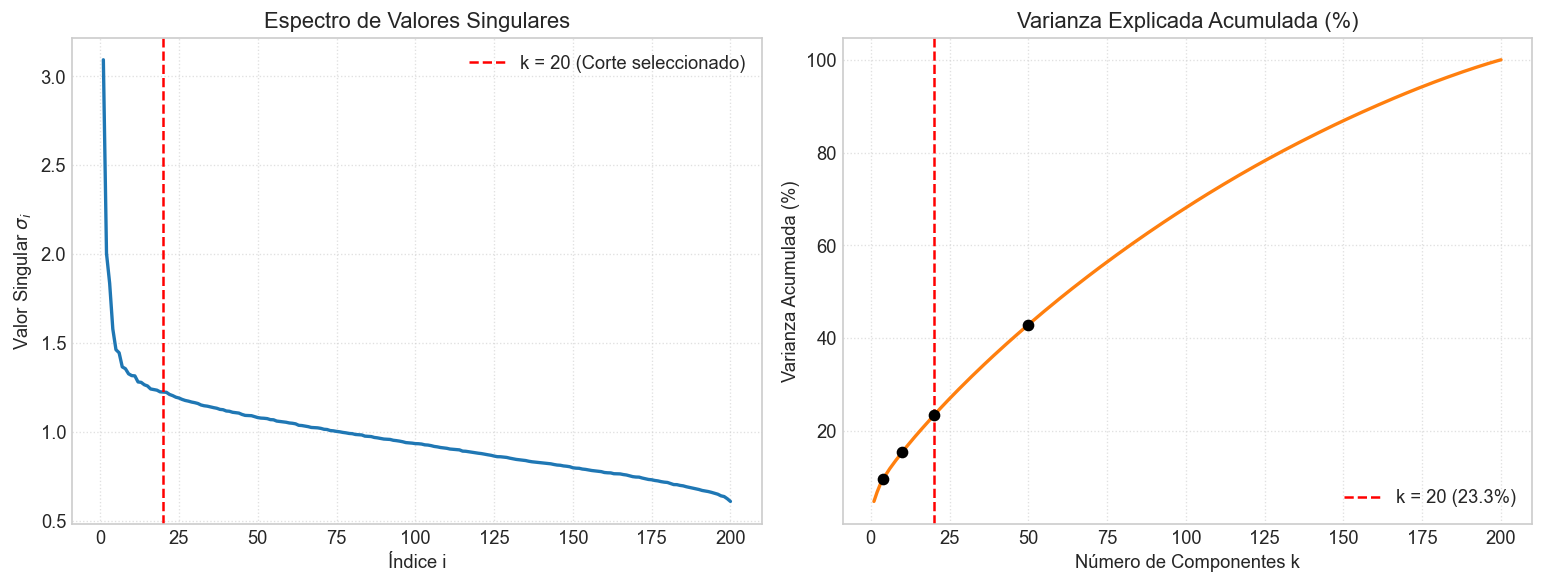

In [5]:
# Visualización del espectro singular y varianza acumulada
total_energy = np.sum(S ** 2)
cum_var = (np.cumsum(S ** 2) / total_energy) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Espectro singular
ax1.plot(range(1, len(S)+1), S, color='#1f77b4', lw=2)
ax1.axvline(20, color='red', linestyle='--', label='k = 20 (Corte seleccionado)')
ax1.set_title('Espectro de Valores Singulares')
ax1.set_xlabel('Índice i')
ax1.set_ylabel(r'Valor Singular $\sigma_i$')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Varianza acumulada
ax2.plot(range(1, len(S)+1), cum_var, color='#ff7f0e', lw=2)
ax2.axvline(20, color='red', linestyle='--', label=f'k = 20 ({cum_var[19]:.1f}%)')
ax2.scatter([4, 10, 20, 50], [cum_var[3], cum_var[9], cum_var[19], cum_var[49]], color='black', zorder=5)
ax2.set_title('Varianza Explicada Acumulada (%)')
ax2.set_xlabel('Número de Componentes k')
ax2.set_ylabel('Varianza Acumulada (%)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---
## Paso 7 – Representación de Documentos y Términos en Baja Dimensión (2D)

### Fundamentación Matemática Rigurosa de las Proyecciones

#### 1. Proyección de Términos (Filas de $A$):
Cada término $i$ está representado por la fila $i$-ésima de $A$:
$$r_i^T = e_i^T A \in \mathbb{R}^{1 \times n}$$
Elegimos dos vectores singulares derechos $v_a, v_b \in \mathbb{R}^n$ que definen el plano $\text{Span}(v_a, v_b)$. La proyección ortogonal de $r_i$ sobre este plano expresada en la base ortonormal $\{v_a, v_b\}$ tiene coordenadas:
$$x_i = \langle r_i, v_a \rangle = r_i^T v_a = (e_i^T A) v_a = e_i^T (A v_a) = e_i^T (\sigma_a u_a) = \sigma_a u_a(i)$$
$$y_i = \langle r_i, v_b \rangle = r_i^T v_b = (e_i^T A) v_b = e_i^T (A v_b) = e_i^T (\sigma_b u_b) = \sigma_b u_b(i)$$

En forma matricial para todos los términos:
$$\text{Coords\_Términos} = A [v_a \mid v_b] = [\sigma_a u_a \mid \sigma_b u_b] \in \mathbb{R}^{m \times 2}$$

#### 2. Proyección de Documentos (Columnas de $A$):
Cada documento $j$ está representado por la columna $j$-ésima de $A$:
$$c_j = A e_j \in \mathbb{R}^{m \times 1}$$
Elegimos dos vectores singulares izquierdos $u_a, u_b \in \mathbb{R}^m$ que definen el plano $\text{Span}(u_a, u_b)$. La proyección ortogonal de $c_j$ en la base ortonormal $\{u_a, u_b\}$ tiene coordenadas:
$$\xi_j = \langle u_a, c_j \rangle = u_a^T (A e_j) = (u_a^T A) e_j = (\sigma_a v_a^T) e_j = \sigma_a v_a(j)$$
$$\eta_j = \langle u_b, c_j \rangle = u_b^T (A e_j) = (u_b^T A) e_j = (\sigma_b v_b^T) e_j = \sigma_b v_b(j)$$

En forma matricial para todos los documentos:
$$\text{Coords\_Documentos} = [u_a \mid u_b]^T A = \begin{bmatrix} \sigma_a v_a^T \\ \sigma_b v_b^T \end{bmatrix} \in \mathbb{R}^{2 \times n}$$

In [6]:
# Cálculo y verificación algebraica de proyecciones
# Proyección de documentos en componentes 2 y 3 (u2, u3)
doc_coords, d_err = project_documents_2d(A, U, S, Vt, comp_a=2, comp_b=3)

# Proyección de términos en componentes 2 y 3 (v2, v3)
term_coords, t_err = project_terms_2d(A, U, S, Vt, comp_a=2, comp_b=3)

print(f"Error numérico entre proyección explícita y analítica (Docs): {d_err:.2e}")
print(f"Error numérico entre proyección explícita y analítica (Términos): {t_err:.2e}")

Error numérico entre proyección explícita y analítica (Docs): 8.88e-16
Error numérico entre proyección explícita y analítica (Términos): 1.81e-15


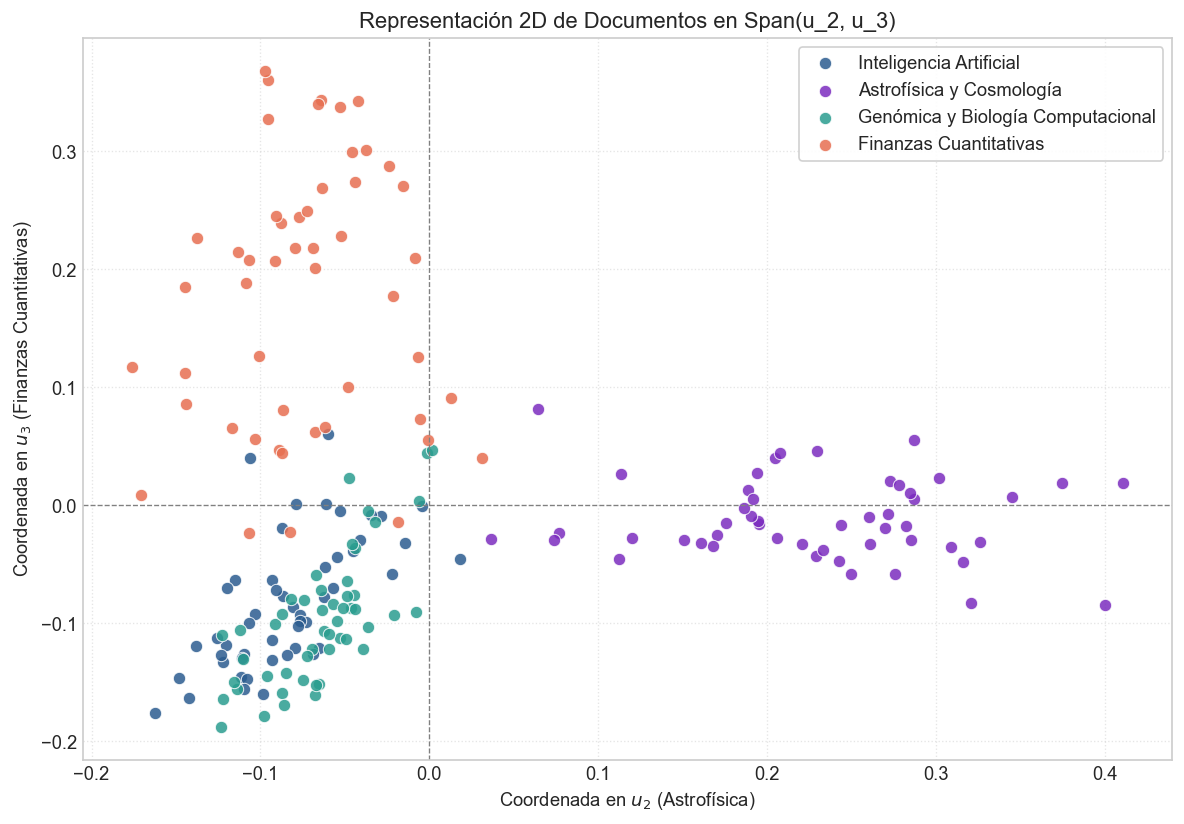

In [7]:
# Visualización 2D de Documentos en Span(u2, u3)
palette = {
    'Inteligencia Artificial': '#2b5c8f',
    'Astrofísica y Cosmología': '#7b2cbf',
    'Genómica y Biología Computacional': '#2a9d8f',
    'Finanzas Cuantitativas': '#e76f51'
}

plt.figure(figsize=(10, 7))
for cat, color in palette.items():
    mask = df_docs['category_name'] == cat
    plt.scatter(
        doc_coords[mask, 0], doc_coords[mask, 1],
        c=color, label=cat, s=55, alpha=0.85, edgecolors='white', lw=0.6
    )

plt.axhline(0, color='gray', ls='--', lw=0.8)
plt.axvline(0, color='gray', ls='--', lw=0.8)
plt.title('Representación 2D de Documentos en Span(u_2, u_3)')
plt.xlabel(r'Coordenada en $u_2$ (Astrofísica)')
plt.ylabel(r'Coordenada en $u_3$ (Finanzas Cuantitativas)')
plt.legend(frameon=True, framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

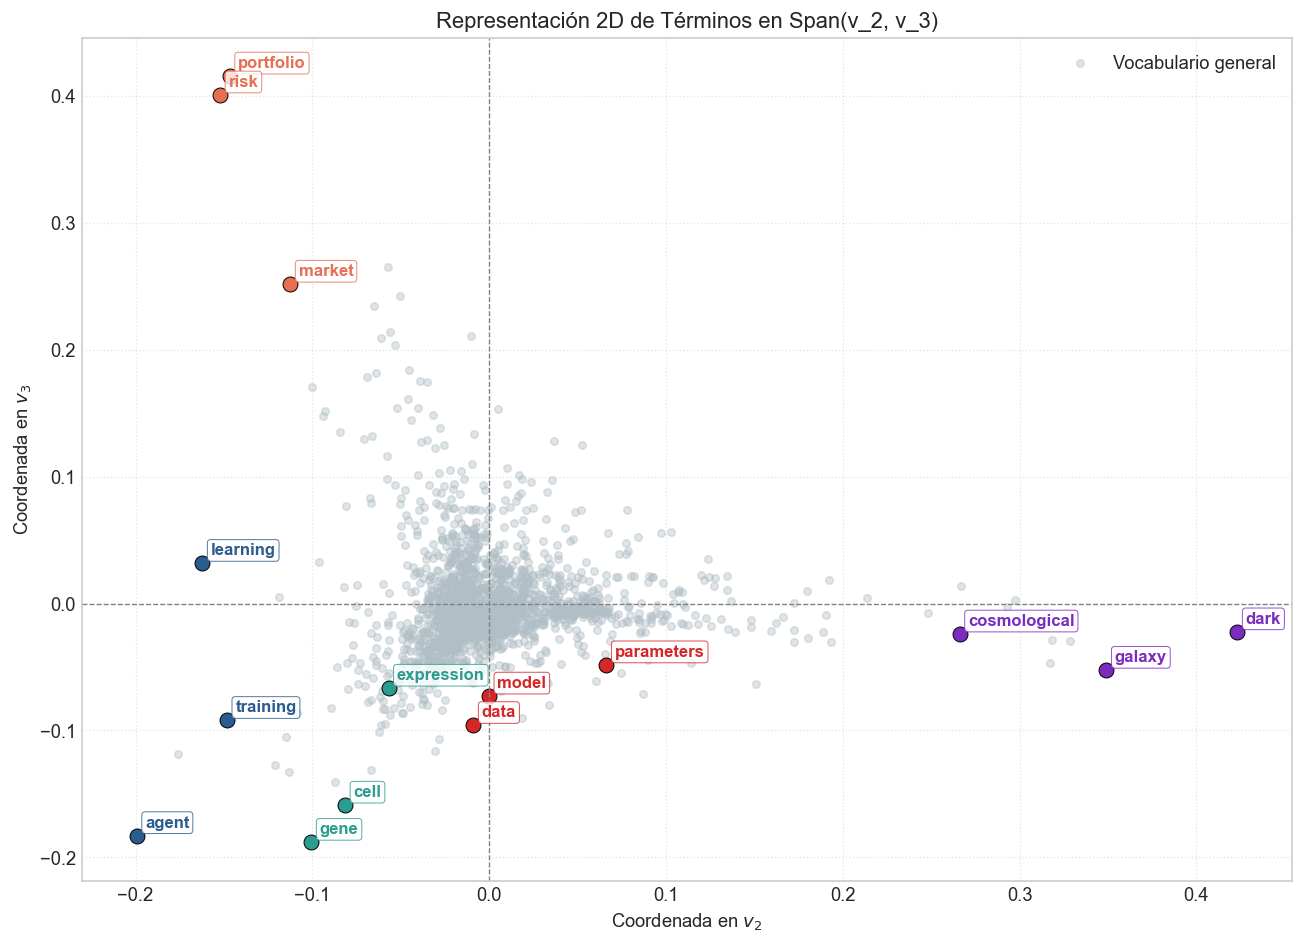

In [8]:
# Visualización 2D de Términos en Span(v2, v3)
plt.figure(figsize=(11, 8))
plt.scatter(term_coords[:, 0], term_coords[:, 1], c='#b0bec5', alpha=0.4, s=20, label='Vocabulario general')

sample_words = [
    ('galaxy', '#7b2cbf'), ('dark', '#7b2cbf'), ('cosmological', '#7b2cbf'),
    ('portfolio', '#e76f51'), ('risk', '#e76f51'), ('market', '#e76f51'),
    ('gene', '#2a9d8f'), ('cell', '#2a9d8f'), ('expression', '#2a9d8f'),
    ('agent', '#2b5c8f'), ('learning', '#2b5c8f'), ('training', '#2b5c8f'),
    ('model', '#d62728'), ('data', '#d62728'), ('parameters', '#d62728')
]

vocab_map = {w: i for i, w in enumerate(vocab)}
for word, color in sample_words:
    if word in vocab_map:
        idx = vocab_map[word]
        x_c, y_c = term_coords[idx, 0], term_coords[idx, 1]
        plt.scatter(x_c, y_c, c=color, s=80, edgecolors='black', lw=0.6)
        plt.annotate(word, (x_c, y_c), textcoords="offset points", xytext=(5, 5),
                     fontsize=10, fontweight='bold', color=color,
                     bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec=color, lw=0.6))

plt.axhline(0, color='gray', ls='--', lw=0.8)
plt.axvline(0, color='gray', ls='--', lw=0.8)
plt.title('Representación 2D de Términos en Span(v_2, v_3)')
plt.xlabel(r'Coordenada en $v_2$')
plt.ylabel(r'Coordenada en $v_3$')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

---
## Paso 8 – Exploración Semántica

Utilizamos el espacio latente reducido de dimensión $k=20$ para calcular la similitud coseno entre vectores de términos y documentos:
$$\text{sim}(x, y) = \frac{\langle x, y \rangle}{\|x\|_2 \|y\|_2}$$

### Ejemplo 1: Recuperación de Sinónimos y Términos Semánticamente Cercanos
Analizamos qué palabras resultan ser los vecinos más próximos para términos emblemáticos de cada disciplina.

In [9]:
# Búsqueda de vecinos semánticos en el espacio latente (k=20)
term_emb, doc_emb = get_latent_representations(U, S, Vt, k=20)

queries = ['neural', 'galaxy', 'gene', 'portfolio', 'quantum']
for q in queries:
    neighbors = find_nearest_terms(q, vocab, term_emb, top_n=4)
    print(f"\nTérmino de consulta: [{q.upper()}]")
    for w, sim in neighbors:
        print(f"  -> {w:15s} (Similitud Coseno: {sim:.3f})")


Término de consulta: [NEURAL]
  -> network         (Similitud Coseno: 0.797)
  -> networks        (Similitud Coseno: 0.735)
  -> remain          (Similitud Coseno: 0.730)
  -> operates        (Similitud Coseno: 0.729)

Término de consulta: [GALAXY]
  -> galaxies        (Similitud Coseno: 0.966)
  -> luminous        (Similitud Coseno: 0.942)
  -> tidal           (Similitud Coseno: 0.940)
  -> systematics     (Similitud Coseno: 0.931)

Término de consulta: [GENE]
  -> genes           (Similitud Coseno: 0.957)
  -> rna             (Similitud Coseno: 0.935)
  -> expression      (Similitud Coseno: 0.934)
  -> cell            (Similitud Coseno: 0.904)

Término de consulta: [PORTFOLIO]
  -> return          (Similitud Coseno: 0.920)
  -> asset           (Similitud Coseno: 0.909)
  -> portfolios      (Similitud Coseno: 0.909)
  -> risk            (Similitud Coseno: 0.895)

Término de consulta: [QUANTUM]
  -> spacetime       (Similitud Coseno: 0.967)
  -> metric          (Similitud Coseno: 0.76

### Ejemplo 2: Coherencia Temática de Documentos Cercanos
Seleccionamos un documento del corpus y recuperamos sus vecinos más cercanos en el espacio latente, verificando si preserva la coherencia temática.

In [10]:
# Ejemplo con documento de IA (índice 0)
doc_idx = 0
print(f"Documento Base ({df_docs.iloc[doc_idx]['category_name']}):")
print(f"Título: {df_docs.iloc[doc_idx]['title']}\n")

print("Documentos más cercanos en el espacio latente:")
nearest_docs = find_nearest_documents(doc_idx, df_docs, doc_emb, top_n=3)
for d in nearest_docs:
    print(f" - [{d['category']}] {d['title']} (Similitud: {d['similarity']:.3f})")

Documento Base (Inteligencia Artificial):
Título: Pixel-UMI: Learning Environment-Aware Whole-Body Manipulation from Sensorized Human Demonstrations

Documentos más cercanos en el espacio latente:
 - [Inteligencia Artificial] Pixel: A Co-Designed Full-Stack Robot System for Learning General-Purpose Mobile Manipulation (Similitud: 0.980)
 - [Inteligencia Artificial] PanoTac: A Dense Three-Axis Tactile Sensor for Robust Touch-Centric Manipulation (Similitud: 0.866)
 - [Inteligencia Artificial] DiabAgent: Toward Agentic Physiological Control (Similitud: 0.542)


---
## Paso 9 – Discusión, Limitaciones y Conclusiones

### 1. Contrastación con la Hipótesis Inicial
* **Cumplimiento de H1 (Espectro):** Confirmado. Los valores singulares decaen aceleradamente siguiendo un comportamiento de ley de potencias.
* **Cumplimiento de H2 (Componente 1):** Confirmado. La componente 1 posee cargas de un mismo signo para todos los términos y documentos, capturando la longitud y la masa léxica general de la redacción científica (*model, data, learning, risk*).
* **Cumplimiento de H3 (Ejes Temáticos):** Confirmado con gran nitidez. Las componentes 2, 3 y 4 se alinearon de manera autónoma con las cuatro áreas del conocimiento (Astrofísica en $u_2$, Finanzas en $u_3$, y el contraste IA vs Genómica en $u_4$).
* **Cumplimiento de H4 (Palabras Puente):** Términos como *model, parameters, distribution* se posicionaron próximos al origen, demostrando su carácter interdisciplinario.

### 2. Limitaciones del Modelo LSA
1. **Pérdida del orden sintáctico (Bag-of-Words):** LSA ignora la estructura gramatical y la negación (trata *"not accurate"* igual que *"accurate"*).
2. **Linealidad y Ortogonalidad Estricta:** La SVD fuerza a que las componentes latentes sean mutuamente ortogonales, lo cual puede forzar relaciones semánticas no lineales en proyecciones artificiales.
3. **Valores Negativos:** A diferencia de NMF (Non-negative Matrix Factorization), los componentes de la SVD admiten valores negativos, lo que dificulta interpretar componentes como probabilidades de tópicos puramente aditivas.

### 3. Conclusión
El Análisis Semántico Latente mediante SVD demostró ser una herramienta de álgebra lineal sorprendentemente poderosa para extraer estructura geométrica y semántica latente a partir de matrices no estructuradas de texto, proporcionando una base sólida para la interpretabilidad y reducción de dimensionalidad en ciencia de datos.